In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Rail profile files are stored locally in the data folder
rail_folder = Path("../data/Profiles/Rail profiles")

sorted(path.name for path in rail_folder.iterdir())

['RProfile 1.FIT',
 'RProfile 1L.BAN',
 'RProfile 1R.BAN',
 'RProfile 2.FIT',
 'RProfile 2L.BAN',
 'RProfile 2R.BAN',
 'RProfile 3.FIT',
 'RProfile 3L.BAN',
 'RProfile 3R.BAN',
 'RProfile 4.FIT',
 'RProfile 4L.BAN',
 'RProfile 4R.BAN',
 'RProfile 5.BAN',
 'RProfile 5.FIT',
 'RProfile 6.BAN',
 'RProfile 6.FIT',
 'RProfile 7.BAN',
 'RProfile 7.FIT']

In [2]:
# Read each BAN file (header lines first, then a blank line, then X, Y, A, C points)
rails = {}

for path in sorted(rail_folder.glob("*.BAN")):
    points = []
    in_points = False

    for line in path.read_text().splitlines():
        line = line.strip()
        if not in_points and line.startswith("ColumnDef="):
            columns = line.split("=")[1].split(",")
        elif not in_points and line == "" and len(points) == 0:
            in_points = True
        elif in_points and line != "":
            points.append([float(value) for value in line.split()])

    rails[path.stem.replace("RProfile ", "")] = pd.DataFrame(points, columns=columns)

# Check that each profile loaded correctly
for name, points in rails.items():
    print(name, points.shape)

1L (335, 4)
1R (294, 3)
2L (303, 3)
2R (306, 3)
3L (316, 3)
3R (324, 3)
4L (315, 3)
4R (399, 3)
5 (323, 4)
6 (330, 4)
7 (363, 4)


**Rail profiles 1-4 have separate left and right files while 5-7 only have one. Need to check with MxV if 5-7 use the same shape for both rails.**

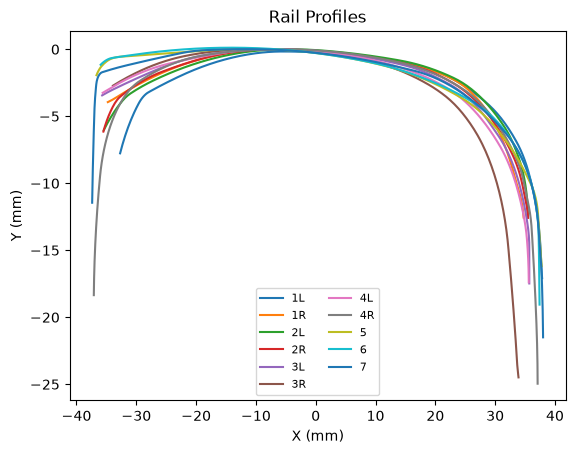

In [3]:
# Plot all rail profiles together
for name, points in rails.items():
    plt.plot(points["X"], points["Y"], label=name)

plt.xlabel("X (mm)")
plt.ylabel("Y (mm)")
plt.title("Rail Profiles")
plt.legend(ncol=2, fontsize=8)
plt.show()

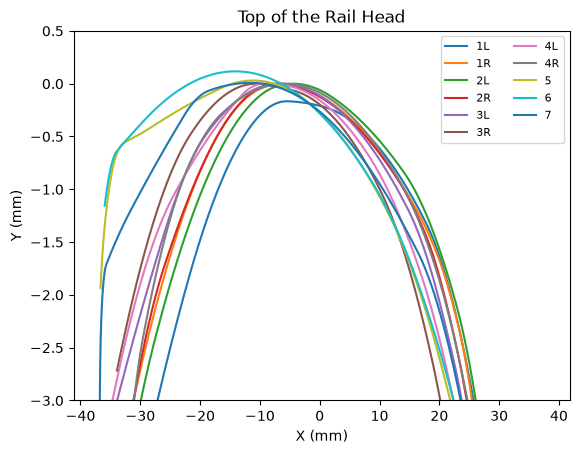

In [4]:
# Zoom in on the top of the rail head
for name, points in rails.items():
    plt.plot(points["X"], points["Y"], label=name)

plt.ylim(-3, 0.5)
plt.xlabel("X (mm)")
plt.ylabel("Y (mm)")
plt.title("Top of the Rail Head")
plt.legend(ncol=2, fontsize=8)
plt.show()

**Profiles 5 and 6 look a lot flatter and wider across the top than the others. Profile 7 is somewhere in between.**

In [5]:
# Estimate crown radius by fitting a parabola within 20 mm of the top of the rail
rail_shape = []

for name, points in rails.items():
    top = points.loc[points["Y"].idxmax()]
    near_top = points[abs(points["X"] - top["X"]) < 20]
    a = np.polyfit(near_top["X"], near_top["Y"], 2)[0]

    # Width of the rail head within 1 mm of the top
    within_1mm = points[points["Y"] > top["Y"] - 1]

    rail_shape.append({
        "Profile": name,
        "Rail_Profile": int(name[0]),
        "Crown_Radius": -1 / (2 * a),
        "Width_1mm": within_1mm["X"].max() - within_1mm["X"].min()
    })

rail_shape = pd.DataFrame(rail_shape)
rail_shape.round(1)

,Profile,Rail_Profile,Crown_Radius,Width_1mm
0,1L,1,122.2,34.3
1,1R,1,141.7,35.4
2,2L,2,144.1,35.1
3,2R,2,140.1,35.2
4,3L,3,159.7,36.2
5,3R,3,147.1,35.8
6,4L,4,153.0,34.8
7,4R,4,171.5,37.4
8,5,5,260.0,43.9
9,6,6,252.4,43.3


In [6]:
# Average the left and right rails so there is one row per rail profile
rail_summary = rail_shape.groupby("Rail_Profile").agg(
    Crown_Radius=("Crown_Radius", "mean"),
    Crown_Radius_Diff=("Crown_Radius", lambda r: r.max() - r.min()),
    Width_1mm=("Width_1mm", "mean")
)

rail_summary.round(1)

,Crown_Radius,Crown_Radius_Diff,Width_1mm
Rail_Profile,,,
1,132.0,19.5,34.8
2,142.1,4.0,35.2
3,153.4,12.5,36.0
4,162.3,18.5,36.1
5,260.0,0.0,43.9
6,252.4,0.0,43.3
7,192.1,0.0,39.7


In [7]:
# Load the merged dataset and keep one row per car, truck, and rail profile
final_data = pd.read_csv("../data/final_merged_data.csv")

truck_data = final_data.groupby(["Car", "Truck", "Rail_Profile"], as_index=False).agg(
    Hunted=("Empty_Truck_Hunted", "first"),
    Critical_Speed=("Min Empty Truck from Acc HS [mph]", "first"),
    Eq_Con=("Min Eq Con 3mm", "first")
)

truck_data.shape

(196, 6)

In [8]:
# Compare rail shape with hunting rate, critical speed, and conicity
rail_results = truck_data.groupby("Rail_Profile").agg(
    Hunting_Rate=("Hunted", "mean"),
    Median_Speed=("Critical_Speed", "median"),
    Mean_Eq_Con=("Eq_Con", "mean")
)

rail_summary = rail_summary.join(rail_results)
rail_summary.sort_values("Crown_Radius").round(3)

,Crown_Radius,Crown_Radius_Diff,Width_1mm,Hunting_Rate,Median_Speed,Mean_Eq_Con
Rail_Profile,,,,,,
1,131.963,19.538,34.823,0.786,60.805,0.280
2,142.077,3.994,35.151,0.786,61.585,0.262
3,153.412,12.536,36.013,0.571,67.250,0.237
4,162.255,18.464,36.097,0.750,64.290,0.221
7,192.073,0.000,39.742,0.607,66.480,0.219
6,252.391,0.000,43.305,0.536,70.560,0.128
5,260.028,0.000,43.926,0.464,80.000,0.112


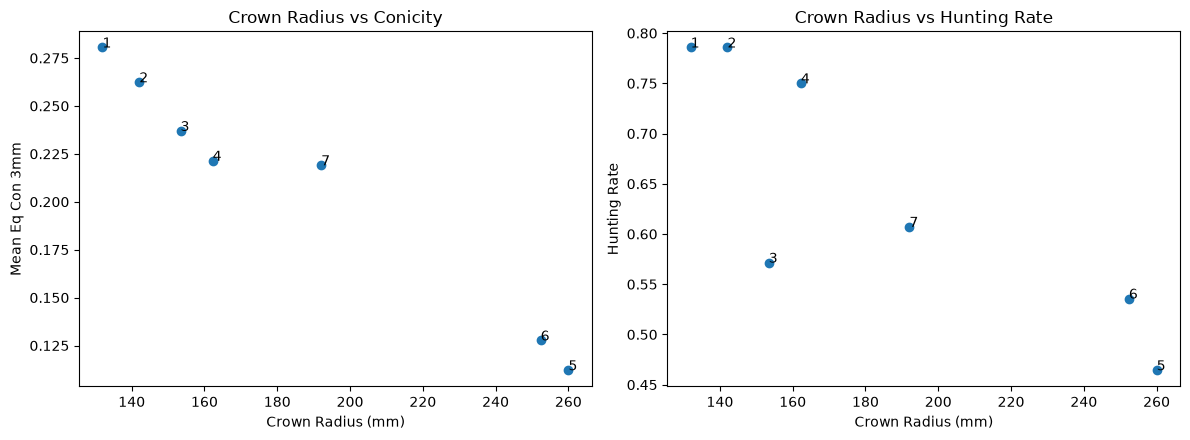

In [9]:
# Visualize crown radius against conicity and hunting rate
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(rail_summary["Crown_Radius"], rail_summary["Mean_Eq_Con"])
axes[1].scatter(rail_summary["Crown_Radius"], rail_summary["Hunting_Rate"])

for rail, row in rail_summary.iterrows():
    axes[0].annotate(str(rail), (row["Crown_Radius"], row["Mean_Eq_Con"]))
    axes[1].annotate(str(rail), (row["Crown_Radius"], row["Hunting_Rate"]))

axes[0].set_xlabel("Crown Radius (mm)")
axes[0].set_ylabel("Mean Eq Con 3mm")
axes[0].set_title("Crown Radius vs Conicity")
axes[1].set_xlabel("Crown Radius (mm)")
axes[1].set_ylabel("Hunting Rate")
axes[1].set_title("Crown Radius vs Hunting Rate")
plt.tight_layout()
plt.show()

In [10]:
# Rank correlation between rail shape and results across the 7 rail profiles
rail_summary.corr(method="spearman").loc[
    ["Crown_Radius", "Crown_Radius_Diff", "Width_1mm"],
    ["Mean_Eq_Con", "Hunting_Rate", "Median_Speed"]
].round(2)

,Mean_Eq_Con,Hunting_Rate,Median_Speed
Crown_Radius,-1.00,-0.88,0.89
Crown_Radius_Diff,0.82,0.69,-0.74
Width_1mm,-1.00,-0.88,0.89


**Flatter rails (larger crown radius) have lower conicity in the exact same order, and hunting mostly follows. Profiles 5 and 6 are the flattest and hunt the least. Profile 4 doesn't fit as well since it hunts almost as much as 1 and 2. Profiles 1 and 4 also have the biggest left-right difference. Only 7 rail profiles though so this is a starting point.**

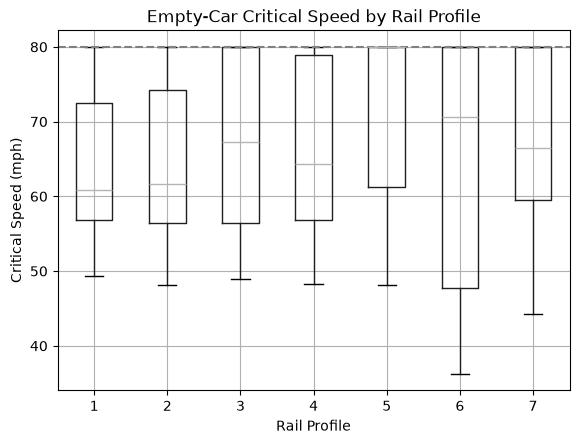

In [11]:
# Compare critical speed across the seven rail profiles
truck_data.boxplot(column="Critical_Speed", by="Rail_Profile")

plt.axhline(80, color="gray", linestyle="--")
plt.xlabel("Rail Profile")
plt.ylabel("Critical Speed (mph)")
plt.title("Empty-Car Critical Speed by Rail Profile")
plt.suptitle("")
plt.show()

In [12]:
# Check how many assessments are at the 80 mph cap
print("At 80 mph:", (truck_data["Critical_Speed"] == 80).sum(), "of", len(truck_data))
print("Max speed:", truck_data["Critical_Speed"].max())

At 80 mph: 70 of 196
Max speed: 80.0


**70 of the 196 assessments are exactly 80 mph and none are higher, so 80 looks like the top speed tested. Profile 6 has the lowest critical speed overall even though it's one of the flattest rails.**

In [13]:
# Check how much of the variation in critical speed comes from the rail profile vs the truck
truck_data["Truck_ID"] = truck_data["Car"].astype(str) + "-" + truck_data["Truck"].astype(str)

overall_mean = truck_data["Critical_Speed"].mean()
total = ((truck_data["Critical_Speed"] - overall_mean) ** 2).sum()

rail_means = truck_data.groupby("Rail_Profile")["Critical_Speed"].transform("mean")
truck_means = truck_data.groupby("Truck_ID")["Critical_Speed"].transform("mean")

print("Rail profile:", round(((rail_means - overall_mean) ** 2).sum() / total, 2))
print("Truck:", round(((truck_means - overall_mean) ** 2).sum() / total, 2))

Rail profile: 0.04
Truck: 0.53


**The truck explains way more of the variation in critical speed (about 53%) than the rail profile (about 4%). So the wheel profiles on each truck matter more than which rail they run on.**

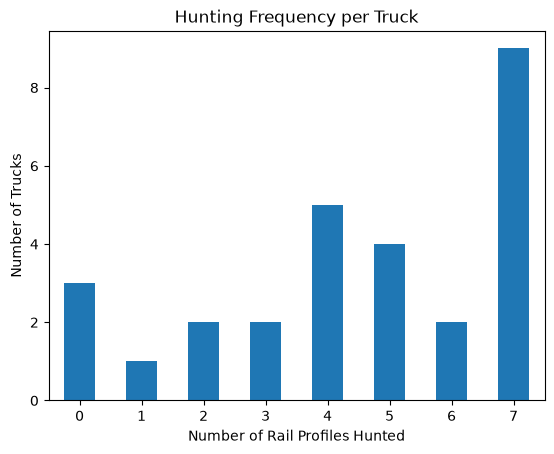

In [14]:
# Count how many of the seven rail profiles each truck hunted on
hunting_table = truck_data.pivot_table(
    index=["Car", "Truck"],
    columns="Rail_Profile",
    values="Hunted",
    aggfunc="first"
).astype(int)

hunting_table["Rails_Hunted"] = hunting_table.sum(axis=1)

hunting_table["Rails_Hunted"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Number of Rail Profiles Hunted")
plt.ylabel("Number of Trucks")
plt.title("Hunting Frequency per Truck")
plt.xticks(rotation=0)
plt.show()

In [15]:
hunting_table.sort_values("Rails_Hunted")

,Rail_Profile,1,2,3,4,5,6,7,Rails_Hunted
Car,Truck,,,,,,,,
2,1,0,0,0,0,0,0,0,0
3,2,0,0,0,0,0,0,0,0
5,2,0,0,0,0,0,0,0,0
12,2,0,0,0,0,0,0,1,1
5,1,1,1,0,0,0,0,0,2
2,2,1,0,0,0,0,0,1,2
4,1,1,1,0,0,0,0,1,3
1,2,1,1,0,1,0,0,0,3
13,1,0,1,0,1,1,1,0,4


**9 trucks hunt on all 7 rail profiles and 3 never hunt. Most trucks are near one end or the other, which could work as groups for clustering (always, sometimes, never).**

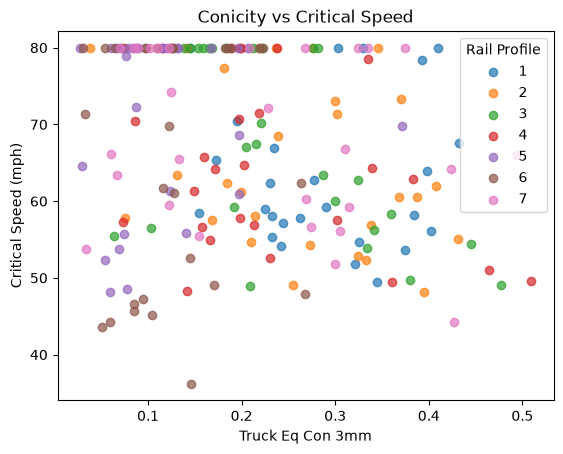

In [16]:
# Compare conicity and critical speed, colored by rail profile
for rail, group in truck_data.groupby("Rail_Profile"):
    plt.scatter(group["Eq_Con"], group["Critical_Speed"], label=rail, alpha=0.7)

plt.xlabel("Truck Eq Con 3mm")
plt.ylabel("Critical Speed (mph)")
plt.title("Conicity vs Critical Speed")
plt.legend(title="Rail Profile")
plt.show()

In [17]:
# Check the relationship between conicity and critical speed within each rail profile
truck_data.groupby("Rail_Profile")[["Eq_Con", "Critical_Speed"]].corr(method="spearman").xs(
    "Eq_Con", level=1
)["Critical_Speed"].round(2)

Rail_Profile
1   -0.18
2   -0.28
3   -0.51
4   -0.27
5    0.16
6    0.15
7   -0.18
Name: Critical_Speed, dtype: float64

In [18]:
# Compare hunting rates above and below a few conicity cutoffs
for cutoff in [0.15, 0.20, 0.25]:
    low = truck_data[truck_data["Eq_Con"] < cutoff]
    high = truck_data[truck_data["Eq_Con"] >= cutoff]
    print("Eq Con", cutoff, "| below:", round(low["Hunted"].mean(), 2), "| above:", round(high["Hunted"].mean(), 2))

Eq Con 0.15 | below: 0.49 | above: 0.73
Eq Con 0.2 | below: 0.52 | above: 0.78
Eq Con 0.25 | below: 0.55 | above: 0.83


**Assessments with Eq Con below 0.20 hunted less often (52% vs 78%). But within a single rail profile conicity is only weakly related to critical speed, and on profiles 5 and 6 it goes the other way. Conicity alone doesn't explain which trucks hunt, so other wheel shape descriptors are worth looking into. Next is comparing the wheel measurements for the trucks that always hunt vs never hunt.**